In [7]:
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
from sklearn.metrics import auc
import pickle
import os

In [2]:
#e15_d16_reg0001
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model_e15_d16_reg0001_test_precision_recall.pickle', 'rb')
pr_test_e15_d16_reg0001=pickle.load(pickle_in)
p_test_e15_d16_reg0001, r_test_e15_d16_reg0001 = pr_test_e15_d16_reg0001
p_test_e15_d16_reg0001 = np.mean(np.array(p_test_e15_d16_reg0001), axis=1)
r_test_e15_d16_reg0001 = np.mean(np.array(r_test_e15_d16_reg0001), axis=1)

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model_e15_d16_reg0001_train_precision_recall.pickle', 'rb')
pr_train_e15_d16_reg0001=pickle.load(pickle_in)
p_train_e15_d16_reg0001, r_train_e15_d16_reg0001 = pr_train_e15_d16_reg0001
p_train_e15_d16_reg0001 = np.mean(np.array(p_train_e15_d16_reg0001), axis=1)
r_train_e15_d16_reg0001 = np.mean(np.array(r_train_e15_d16_reg0001), axis=1)

**Finding optimal alpha value**

In [3]:
#finding optimal alpha value

files = []
files.append('DHS_model_e15_d16_reg0.0001_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0001_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0002_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0002_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0003_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0003_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0004_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0004_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0005_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0005_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0006_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0006_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0007_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0007_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0008_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0008_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0009_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.0009_lr01_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.001_lr01_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0.001_lr01_train_precision_recall_CT20211028.pickle')

In [4]:
#finding optimal alpha value
precision_alpha = []
recall_alpha = []
counter = 0
for file_name in files:
    file_path = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/', file_name)
    pickle_in = open(file_path, 'rb')
    pr = pickle.load(pickle_in)
    p, r = pr
    p = list(np.mean(np.array(p), axis=1))
    r = list(np.mean(np.array(r), axis=1))
    precision_alpha.append(p)
    recall_alpha.append(r)

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (epochs=15, k=16 components, learning rate=0.01) with varying values of alpha')

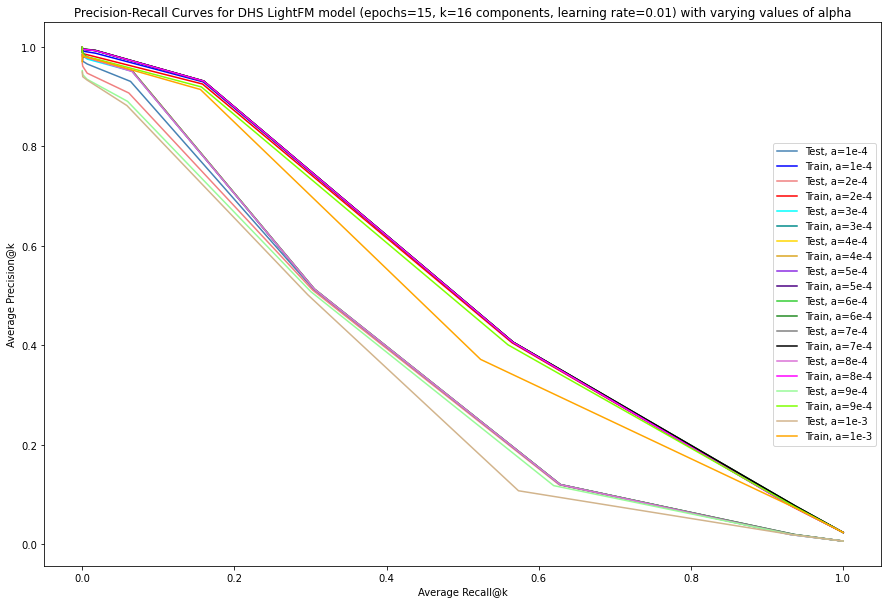

In [5]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
c = ['steelblue', 'blue', 'lightcoral', 'red', 'cyan', 'darkcyan', 'gold', 'goldenrod', 'blueviolet', 'indigo', 'limegreen', 'forestgreen', 'grey', 'black', 'orchid', 'magenta', 'palegreen', 'chartreuse', 'tan', 'orange']
l = ['Test, a=1e-4', 'Train, a=1e-4', 'Test, a=2e-4', 'Train, a=2e-4', 'Test, a=3e-4', 'Train, a=3e-4', 'Test, a=4e-4', 'Train, a=4e-4', 'Test, a=5e-4', 'Train, a=5e-4', 'Test, a=6e-4', 'Train, a=6e-4', 'Test, a=7e-4', 'Train, a=7e-4', 'Test, a=8e-4', 'Train, a=8e-4', 'Test, a=9e-4', 'Train, a=9e-4', 'Test, a=1e-3', 'Train, a=1e-3']

fig = plt.figure(figsize=(15,10))
fig.patch.set_facecolor('white')
for i in range(len(precision_alpha)):
    plt.plot(recall_alpha[i], precision_alpha[i], color=c[i])
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(l, loc='right')
plt.title('Precision-Recall Curves for DHS LightFM model (epochs=15, k=16 components, learning rate=0.01) with varying values of alpha')

In [6]:
max_auc = 0
for i in range(0, len(precision_alpha), 2):
    max_auc_store = max_auc
    max_auc = max(auc(recall_alpha[i], precision_alpha[i]), max_auc)
    if max_auc != max_auc_store:
        top_alpha = files[i]
print('Top alpha value:', top_alpha)
print('AUC:', max_auc)

Top alpha value: DHS_model_e15_d16_reg0.0007_lr01_test_precision_recall_CT20211028.pickle
AUC: 0.36321325083767125


**Finding optimal number of epochs to train on**

In [7]:
files = []
files.append('DHS_model_e5_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e5_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e10_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e10_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e15_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e20_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e20_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e25_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e25_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e30_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e30_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e40_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e40_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e50_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e50_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e75_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e75_d16_reg0001_train_precision_recall_CT20211028.pickle')
files.append('DHS_model_e100_d16_reg0001_test_precision_recall_CT20211028.pickle')
files.append('DHS_model_e100_d16_reg0001_train_precision_recall_CT20211028.pickle')

In [8]:
precision_epochs = []
recall_epochs = []
counter = 0
for file_name in files:
    file_path = os.path.join('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/', file_name)
    pickle_in = open(file_path, 'rb')
    pr = pickle.load(pickle_in)
    p, r = pr
    p = list(np.mean(np.array(p), axis=1))
    r = list(np.mean(np.array(r), axis=1))
    precision_epochs.append(p)
    recall_epochs.append(r)

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model (k=16 components, alpha=1e-4) trained for different epochs')

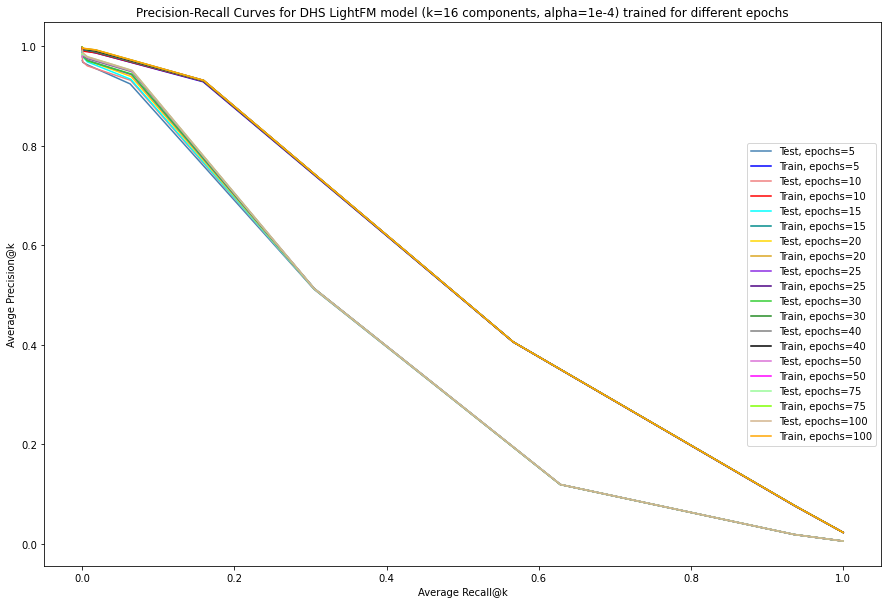

In [9]:
#Plot precision-recall curves for train and test data (15 epochs, 16 dimensions)
c = ['steelblue', 'blue', 'lightcoral', 'red', 'cyan', 'darkcyan', 'gold', 'goldenrod', 'blueviolet', 'indigo', 'limegreen', 'forestgreen', 'grey', 'black', 'orchid', 'magenta', 'palegreen', 'chartreuse', 'tan', 'orange']
l = ['Test, epochs=5', 'Train, epochs=5', 'Test, epochs=10', 'Train, epochs=10', 'Test, epochs=15', 'Train, epochs=15', 'Test, epochs=20', 'Train, epochs=20', 'Test, epochs=25', 'Train, epochs=25', 'Test, epochs=30', 'Train, epochs=30', 'Test, epochs=40', 'Train, epochs=40', 'Test, epochs=50', 'Train, epochs=50', 'Test, epochs=75', 'Train, epochs=75', 'Test, epochs=100', 'Train, epochs=100']

fig = plt.figure(figsize=(15,10))
fig.patch.set_facecolor('white')
for i in range(len(precision_alpha)):
# for i in range(20):
    plt.plot(recall_epochs[i], precision_epochs[i], color=c[i])
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(l, loc='right')
plt.title('Precision-Recall Curves for DHS LightFM model (k=16 components, alpha=1e-4) trained for different epochs')

In [10]:
max_auc = 0
for i in range(0, len(precision_epochs), 2):
    max_auc_store = max_auc
    max_auc = max(auc(recall_epochs[i], precision_epochs[i]), max_auc)
    if max_auc != max_auc_store:
        top_alpha = files[i]
print('Top epoch value:', top_alpha)
print('AUC:', max_auc)

Top epoch value: DHS_model_e100_d16_reg0001_test_precision_recall_CT20211028.pickle
AUC: 0.36293665564627214


**Model trained on signal data**

In [37]:
#e15_d16_reg0001_lr01_rs3_signal

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_signal_model_e15_d16_reg0.0001_lr01_rs3_test_precision_recall_CT20211028.pickle', 'rb')
pr_test_e15_d16_reg0001_lr01_rs3_signal = pickle.load(pickle_in)
p_test_e15_d16_reg0001_lr01_rs3_signal, r_test_e15_d16_reg0001_lr01_rs3_signal = pr_test_e15_d16_reg0001_lr01_rs3_signal
p_test_e15_d16_reg0001_lr01_rs3_signal = np.mean(np.array(p_test_e15_d16_reg0001_lr01_rs3_signal), axis=1)
r_test_e15_d16_reg0001_lr01_rs3_signal = np.mean(np.array(r_test_e15_d16_reg0001_lr01_rs3_signal), axis=1)

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_signal_model_e15_d16_reg0.0001_lr01_rs3_train_precision_recall_CT20211028.pickle', 'rb')
pr_train_e15_d16_reg0001_lr01_rs3_signal = pickle.load(pickle_in)
p_train_e15_d16_reg0001_lr01_rs3_signal, r_train_e15_d16_reg0001_lr01_rs3_signal = pr_train_e15_d16_reg0001_lr01_rs3_signal
p_train_e15_d16_reg0001_lr01_rs3_signal = np.mean(np.array(p_train_e15_d16_reg0001_lr01_rs3_signal), axis=1)
r_train_e15_d16_reg0001_lr01_rs3_signal = np.mean(np.array(r_train_e15_d16_reg0001_lr01_rs3_signal), axis=1)

Text(0.5, 1.0, 'Precision-Recall Curves for DHS Signal and Presence/Absence LightFM models\nepochs=15, k=16 components, alpha=1e-4, learning rate=0.01')

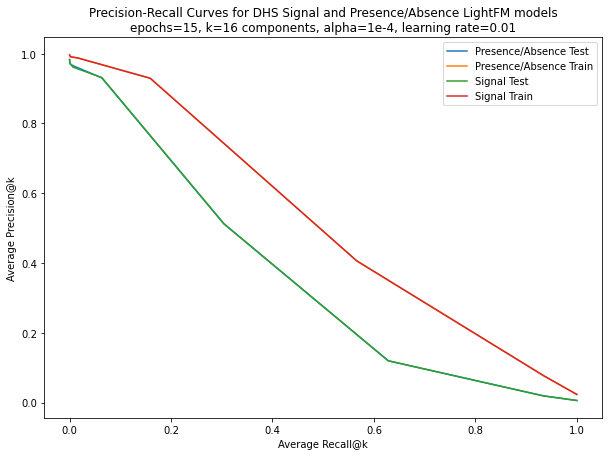

In [38]:
fig = plt.figure(figsize=(10,7))
fig.patch.set_facecolor('white')
plt.plot(recall_alpha[0], precision_alpha[0])
plt.plot(recall_alpha[1], precision_alpha[1])
plt.plot(r_test_e15_d16_reg0001_lr01_rs3_signal, p_test_e15_d16_reg0001_lr01_rs3_signal)
plt.plot(r_train_e15_d16_reg0001_lr01_rs3_signal, p_train_e15_d16_reg0001_lr01_rs3_signal)

plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Presence/Absence Test', 'Presence/Absence Train', 'Signal Test', 'Signal Train'])
plt.title('Precision-Recall Curves for DHS Signal and Presence/Absence LightFM models\nepochs=15, k=16 components, alpha=1e-4, learning rate=0.01')

In [24]:
print(p_test_e15_d16_reg0001_lr01_rs3_signal)
print(precision_alpha[0])

[0.9686221  0.96302865 0.96024557 0.92919918 0.51236071 0.11967663
 0.01900688 0.00579427]
[0.9836289222373806, 0.9712141882673944, 0.9655115961800819, 0.9305770804911324, 0.5121613915416099, 0.11960736698499318, 0.018997060027285132, 0.005794269672474505]


**Comparing first model to top model**

In [4]:
#DHS_model30
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model30_test_precision_recall_CT20211028.pickle', 'rb')
pr_test_e30=pickle.load(pickle_in)
p_test_e30, r_test_e30 = pr_test_e30
p_test_e30 = np.mean(np.array(p_test_e30), axis=1)
r_test_e30 = np.mean(np.array(r_test_e30), axis=1)

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model30_train_precision_recall_CT20211028.pickle', 'rb')
pr_train_e30=pickle.load(pickle_in)
p_train_e30, r_train_e30 = pr_train_e30
p_train_e30 = np.mean(np.array(p_train_e30), axis=1)
r_train_e30 = np.mean(np.array(r_train_e30), axis=1)

In [3]:
#e15_d16_reg0.0001
pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model_e15_d16_reg0.0007_lr01_test_precision_recall_CT20211028.pickle', 'rb')
pr_test_e15_d16_reg0007_lr01 = pickle.load(pickle_in)
p_test_e15_d16_reg0007_lr01, r_test_e15_d16_reg0007_lr01 = pr_test_e15_d16_reg0007_lr01
p_test_e15_d16_reg0007_lr01 = np.mean(np.array(p_test_e15_d16_reg0007_lr01), axis=1)
r_test_e15_d16_reg0007_lr01 = np.mean(np.array(r_test_e15_d16_reg0007_lr01), axis=1)

pickle_in = open('/home/ctrader/AG/AugmentedGenomics/recommendersystems/lightfm/DHS/precision_recall_results/DHS_model_e15_d16_reg0.0007_lr01_train_precision_recall_CT20211028.pickle', 'rb')
pr_train_e15_d16_reg0007_lr01=pickle.load(pickle_in)
p_train_e15_d16_reg0007_lr01, r_train_e15_d16_reg0007_lr01 = pr_train_e15_d16_reg0007_lr01
p_train_e15_d16_reg0007_lr01 = np.mean(np.array(p_train_e15_d16_reg0007_lr01), axis=1)
r_train_e15_d16_reg0007_lr01 = np.mean(np.array(r_train_e15_d16_reg0007_lr01), axis=1)

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM models\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]')

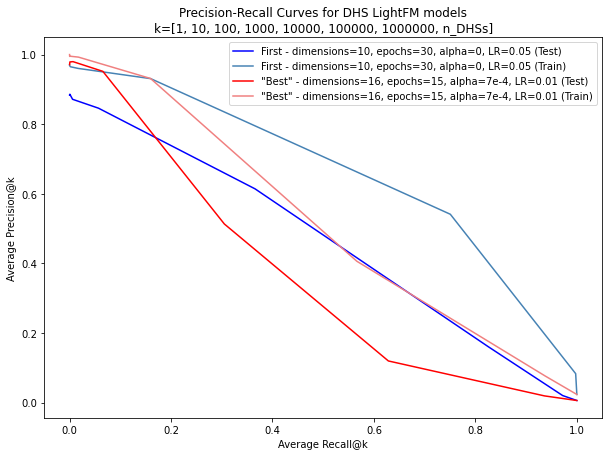

In [5]:
fig = plt.figure(figsize=(10,7))
fig.patch.set_facecolor('white')
plt.plot(r_test_e30, p_test_e30, color='blue')
plt.plot(r_train_e30, p_train_e30, color='steelblue')
plt.plot(r_test_e15_d16_reg0007_lr01, p_test_e15_d16_reg0007_lr01, color='red')
plt.plot(r_train_e15_d16_reg0007_lr01, p_train_e15_d16_reg0007_lr01, color='lightcoral')

plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['First - dimensions=10, epochs=30, alpha=0, LR=0.05 (Test)', 'First - dimensions=10, epochs=30, alpha=0, LR=0.05 (Train)', '"Best" - dimensions=16, epochs=15, alpha=7e-4, LR=0.01 (Test)', '"Best" - dimensions=16, epochs=15, alpha=7e-4, LR=0.01 (Train)'])
plt.title('Precision-Recall Curves for DHS LightFM models\nk=[1, 10, 100, 1000, 10000, 100000, 1000000, n_DHSs]')

In [8]:
print(p_test_e30)
print(p_test_e15_d16_reg0007_lr01)
print()
print(p_train_e30)
print(p_train_e15_d16_reg0007_lr01)

[0.8840382  0.88594816 0.87148704 0.84591542 0.61405184 0.16079407
 0.01997696 0.00579427]
[0.97135061 0.97885402 0.97967258 0.95175853 0.51315771 0.11944333
 0.01904249 0.00579427]

[0.96998636 0.96821282 0.96503411 0.96026739 0.93085744 0.54105738
 0.08296479 0.02317708]
[1.         0.99481583 0.99517053 0.99270259 0.93134475 0.4059205
 0.07616699 0.02317708]
